In [3]:
import pandas as pd 
pelagos = pd.read_excel("Pelagos_Preprocessed_All_Languages.xlsx")
gea = pd.read_excel("Gea_Preprocessed_All_Languages.xlsx")

print("Pelagos reviews:", len(pelagos))
print("Gea reviews:", len(gea))
print("Total reviews:", len(pelagos) + len(gea))

Pelagos reviews: 878
Gea reviews: 249
Total reviews: 1127


In [4]:
import pandas as pd

pelagos = pd.read_excel("Pelagos_Preprocessed_All_Languages.xlsx")
gea = pd.read_excel("Gea_Preprocessed_All_Languages.xlsx")

print("Pelagos reviews:", len(pelagos))
print("Gea reviews:", len(gea))
print("Total reviews:", len(pelagos) + len(gea))

Pelagos reviews: 878
Gea reviews: 249
Total reviews: 1127


In [5]:
rating_summary = pd.DataFrame({
"Pelagos": [
pelagos["Rating"].count(),
pelagos["Rating"].mean(),
pelagos["Rating"].median(),
pelagos["Rating"].std(),
pelagos["Rating"].min(),
pelagos["Rating"].max()
],
"Gea": [
gea["Rating"].count(),
gea["Rating"].mean(),
gea["Rating"].median(),
gea["Rating"].std(),
gea["Rating"].min(),
gea["Rating"].max()
]
}, index=[
"Number of ratings",
"Mean rating",
"Median rating",
"Standard deviation",
"Minimum rating",
"Maximum rating"
])

rating_summary.round(2)

,Pelagos,Gea
Number of ratings,876.00,241.00
Mean rating,4.70,4.76
Median rating,5.00,5.00
Standard deviation,0.84,0.68
Minimum rating,1.00,0.50
Maximum rating,5.00,5.00


In [11]:
#Convert review dates to datetime
pelagos["Review Date"] = pd.to_datetime(
    pelagos["Review Date"], errors="coerce"
)
gea["Review Date"] = pd.to_datetime(
    gea["Review Date"], errors="coerce"
)

#creating year variables
pelagos["Year"] = pelagos["Review Date"].dt.year
gea["Year"] = gea["Review Date"].dt.year

#counting reviews per year
year_summary = pd.DataFrame({
  "Pelagos": pelagos["Year"].value_counts().sort_index(),
  "Gea": gea["Year"].value_counts().sort_index()
    }).fillna(0).astype(int)

year_summary

/tmp/ipykernel_1409/3374824167.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  pelagos["Review Date"] = pd.to_datetime(
/tmp/ipykernel_1409/3374824167.py:5: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  gea["Review Date"] = pd.to_datetime(


,Pelagos,Gea
Year,,
2022,138,49
2023,201,54
2024,305,76
2025,159,45
2026,75,15


In [13]:
#Review platform distribution


pelagos_platforms = pelagos["Review Site"].value_counts(dropna=False)
gea_platforms = gea["Review Site"].value_counts(dropna=False)

print("PELAGOS REVIEW PLATFORMS")
print(pelagos_platforms)

print("\nGEA REVIEW PLATFORMS")
print(gea_platforms)

print("\nCHECK:")
print("Pelagos total:", pelagos_platforms.sum())
print("Gea total:", gea_platforms.sum())

PELAGOS REVIEW PLATFORMS
Review Site
Google          313
TripAdvisor     165
Ctrip           133
Booking.com     108
Expedia          74
Agoda            45
Hotels.com       17
Priceline        15
Facebook          2
Travelocity       2
TabletHotels      1
Qunar             1
Orbitz            1
4TravelJapan      1
Name: count, dtype: int64

GEA REVIEW PLATFORMS
Review Site
TripAdvisor    54
Ctrip          47
NaN            44
Expedia        42
Booking.com    37
Hotels.com     10
Agoda           8
Priceline       7
Name: count, dtype: int64

CHECK:
Pelagos total: 878
Gea total: 249


In [17]:
#Language distribution

pelagos_languages = pelagos["Language"].value_counts(dropna=False)
gea_languages = gea["Language"].value_counts(dropna=False)

print("Pelagos Languages")
print(pelagos_languages)

print("\nGea Languages")
print(gea_languages)

print("\nCheck:")
print("Pelagos total:", pelagos_languages.sum())
print("Gea total:", gea_languages.sum())

Pelagos Languages
Language
English                  667
NaN                       68
Japanese                  26
Portuguese                23
Chinese (Traditional)     18
Spanish                   16
French                    16
German                    12
Italian                    7
Korean                     4
Chinese (Simplified)       4
Russian                    4
Polish                     3
Arabic                     3
Danish                     2
Turkish                    2
Hebrew                     2
Dutch                      1
Name: count, dtype: int64

Gea Languages
Language
English                  202
Portuguese                15
German                     7
French                     6
Japanese                   6
Spanish                    5
Chinese (Traditional)      3
Korean                     1
Italian                    1
Romanian                   1
Hebrew                     1
Swedish                    1
Name: count, dtype: int64

Check:
Pelagos total: 878


In [18]:
# Create English subsets
pelagos_eng = pelagos[pelagos["Language"] == "English"].copy()
gea_eng = gea[gea["Language"] == "English"].copy()

# Calculate review length in words
pelagos_eng["Word_Count"] = pelagos_eng["Review_Text"].astype(str).str.split().str.len()
gea_eng["Word_Count"] = gea_eng["Review_Text"].astype(str).str.split().str.len()

# Review length summary
length_summary = pd.DataFrame({
"Pelagos": [
len(pelagos_eng),
pelagos_eng["Word_Count"].mean(),
pelagos_eng["Word_Count"].median(),
pelagos_eng["Word_Count"].min(),
pelagos_eng["Word_Count"].max()
],
"Gea": [
len(gea_eng),
gea_eng["Word_Count"].mean(),
gea_eng["Word_Count"].median(),
gea_eng["Word_Count"].min(),
gea_eng["Word_Count"].max()
]
}, index=[
"English reviews",
"Mean words",
"Median words",
"Minimum words",
"Maximum words"
])

length_summary.round(2)

,Pelagos,Gea
English reviews,667.00,202.00
Mean words,75.49,76.26
Median words,42.00,46.00
Minimum words,1.00,1.00
Maximum words,822.00,717.00


Matplotlib is building the font cache; this may take a moment.


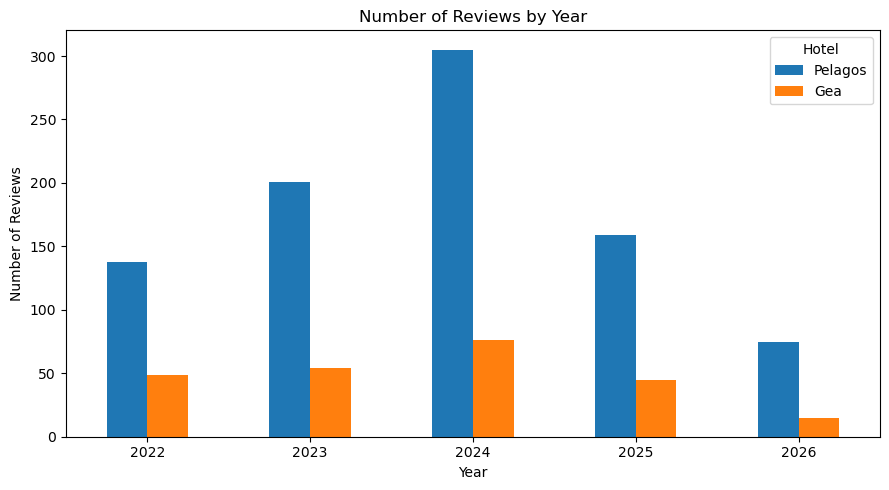

In [20]:
import matplotlib.pyplot as plt

#Reviews per year
year_summary.plot(
    kind="bar",
    figsize=(9,5)
)

plt.title("Number of Reviews by Year")
plt.xlabel("Year")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.legend(title="Hotel")
plt.tight_layout()

plt.show()
           

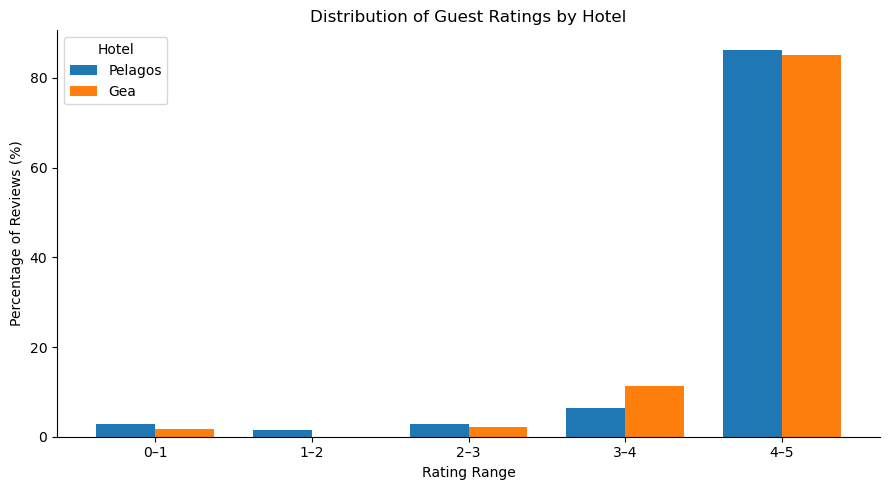

In [23]:
#Rating distribution for both hotels 
import pandas as pd
import matplotlib.pyplot as plt

# Create rating bands
bins = [0, 1, 2, 3, 4, 5]
labels = ["0–1", "1–2", "2–3", "3–4", "4–5"]

pelagos["Rating_Band"] = pd.cut(
pelagos["Rating"],
bins=bins,
labels=labels,
include_lowest=True
)

gea["Rating_Band"] = pd.cut(
gea["Rating"],
bins=bins,
labels=labels,
include_lowest=True
)

# Calculate percentage of reviews in each rating band
pelagos_pct = (
pelagos["Rating_Band"]
.value_counts(normalize=True, sort=False) * 100
)

gea_pct = (
gea["Rating_Band"]
.value_counts(normalize=True, sort=False) * 100
)

rating_plot = pd.DataFrame({
"Pelagos": pelagos_pct,
"Gea": gea_pct
})

ax = rating_plot.plot(
kind="bar",
figsize=(9, 5),
width=0.75
)

plt.title("Distribution of Guest Ratings by Hotel")
plt.xlabel("Rating Range")
plt.ylabel("Percentage of Reviews (%)")
plt.xticks(rotation=0)
plt.legend(title="Hotel")

# Remove unnecessary borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()